# Breakout Room #1 — Apriori: ¿qué se compra junto?

**Objetivo:**
- Encontrar qué productos se compran juntos en una cafetería (reglas de asociación).
- Distinguir una regla **útil** de una regla que solo parece buena porque el producto es popular.
- Decidir qué combos ofrecer en caja: venta cruzada para subir el **ARPU**.

Datos: la misma base de clientes de Starbucks Rewards (2,000 clientes), ahora con **qué compraron en cada orden**
(`orders.csv`: una fila por producto de una orden). Donde dice **`# TODO`** hay algo para que ustedes completen.

> Tres números que van a usar todo el rato. Para una regla **A → B**:
> - **Soporte** = en qué % de *todas* las canastas aparecen A y B juntos.
> - **Confianza** = de las canastas que tienen A, en qué % también está B.
> - **Lift** = confianza ÷ (% de canastas que tienen B). Lift > 1: se compran juntos *más* de lo normal. Lift ≈ 1: no hay relación.

In [ ]:
# En Google Colab, descomenten la siguiente línea:
!pip install mlxtend

  Using cached mlxtend-0.24.0-py3-none-any.whl.metadata (7.3 kB)
INFO: pip is looking at multiple versions of mlxtend to determine which version is compatible with other requirements. This could take a while.
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 14.0 MB/s  0:00:00


In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, association_rules

warnings.filterwarnings("ignore")
VERDE, OSCURO, NARANJA, GRIS = "#00704A", "#11241C", "#C4512F", "#9A988E"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

orders = pd.read_csv("data/orders.csv", parse_dates=["order_date"])
items = pd.read_csv("data/items.csv")
n_ord = orders["order_id"].nunique()
print(f"{n_ord:,} órdenes · {orders['customer_id'].nunique():,} clientes · {orders['item'].nunique()} productos · "
      f"{len(orders)/n_ord:.2f} productos por orden")
orders.head()

14,579 órdenes · 2,000 clientes · 29 productos · 2.01 productos por orden


,order_id,customer_id,order_date,item
0,1,1,2025-02-08,Chocolate Caliente
1,1,1,2025-02-08,Muffin
2,1,1,2025-02-08,Agua
3,2,1,2025-03-28,Refresher
4,3,1,2025-04-04,Chocolate Caliente


## Paso 1 — la canasta

Cada **orden** es una canasta. Convertimos la tabla en una matriz de verdadero/falso: una fila por orden,
una columna por producto (`True` = el producto va en esa canasta).

(14579, 29)


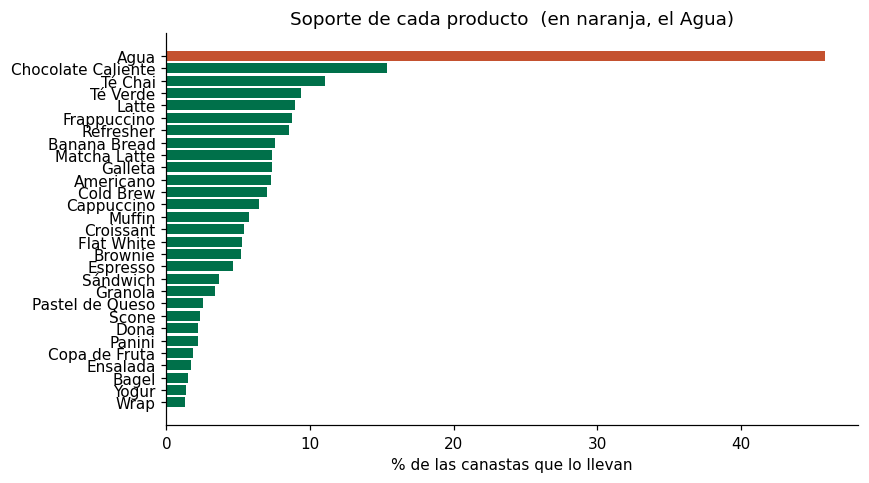

In [4]:
canastas = pd.crosstab(orders["order_id"], orders["item"]).astype(bool)
print(canastas.shape)

soporte = canastas.mean().sort_values(ascending=False)     # % de canastas que llevan cada producto
fig, ax = plt.subplots(figsize=(8, 4.5))
colores = [NARANJA if i == "Agua" else VERDE for i in soporte.index]
ax.barh(soporte.index[::-1], soporte.values[::-1] * 100, color=colores[::-1])
ax.set_xlabel("% de las canastas que lo llevan")
ax.set_title("Soporte de cada producto  (en naranja, el Agua)")
plt.tight_layout(); plt.show()

## Paso 2 — calculen una regla a mano

Antes de dejar que una librería lo haga, calculen **Latte → Croissant** (las personas que compran Latte, ¿compran Croissant?).

In [5]:
N = len(canastas)
n_A  = canastas["Latte"].sum()                              # canastas con Latte
n_B  = canastas["Croissant"].sum()                          # canastas con Croissant
n_AB = (canastas["Latte"] & canastas["Croissant"]).sum()    # canastas con ambos

# TODO 1: calculen las tres métricas con n_A, n_B, n_AB y N.
soporte_AB = n_AB / N
confianza  = n_AB / n_A
lift       = confianza / (n_B / N)

print(f"Soporte {soporte_AB:.3f} · Confianza {confianza:.3f} · Lift {lift:.2f}")

Soporte 0.029 · Confianza 0.324 · Lift 5.99


Soporte: proporción de canastas que contienen ambos productos.

Confianza: probabilidad de comprar Croissant dado que ya compró Latte.

Lift: cuánto aumenta la probabilidad de comprar Croissant cuando se compra Latte, comparado con comprar Croissant “al azar”.

## Paso 3 — Apriori hace lo mismo con todas las parejas

`apriori` encuentra los productos (y combinaciones) que aparecen en al menos `min_support` de las canastas.
`association_rules` convierte eso en reglas A → B con confianza y lift. Nos quedamos con reglas de un producto a otro.

In [6]:
frecuentes = apriori(canastas, min_support=0.01, use_colnames=True)
reglas = association_rules(frecuentes, metric="lift", min_threshold=1.0)
reglas = reglas[(reglas["antecedents"].apply(len) == 1) & (reglas["consequents"].apply(len) == 1)].copy()
reglas["A"] = reglas["antecedents"].apply(lambda s: list(s)[0])
reglas["B"] = reglas["consequents"].apply(lambda s: list(s)[0])
reglas = reglas[["A", "B", "support", "confidence", "lift"]].reset_index(drop=True)
print(f"{len(frecuentes)} conjuntos frecuentes · {len(reglas)} reglas A → B")
reglas.sort_values("lift", ascending=False).head(10).round(3)

68 conjuntos frecuentes · 48 reglas A → B


,A,B,support,confidence,lift
45,Matcha Latte,Granola,0.020,0.268,7.861
44,Granola,Matcha Latte,0.020,0.577,7.861
23,Sándwich,Americano,0.018,0.504,6.916
22,Americano,Sándwich,0.018,0.251,6.916
39,Latte,Croissant,0.029,0.324,5.987
38,Croissant,Latte,0.029,0.537,5.987
46,Pastel de Queso,Refresher,0.012,0.451,5.280
47,Refresher,Pastel de Queso,0.012,0.137,5.280
33,Muffin,Cappuccino,0.018,0.317,4.912
32,Cappuccino,Muffin,0.018,0.281,4.912


## Paso 4 — quédense con las reglas buenas

Una regla útil para una campaña necesita **las dos cosas**: que pase seguido (confianza) y que sea más que casualidad (lift).
Filtren reglas con **confianza ≥ 0.25 y lift ≥ 1.5**.

In [9]:
# TODO 2: filtren 'reglas' con confianza >= 0.25 Y lift >= 1.5, y ordenen por lift (de mayor a menor).
#buenas = reglas[ ... ].sort_values("lift", ascending=False)      # <-- reemplacen el ...
buenas = reglas[
    (reglas["confidence"] >= 0.25) &
    (reglas["lift"] >= 1.5)
].sort_values("lift", ascending=False)

print(f"{len(buenas)} reglas buenas")
buenas.round(3)

15 reglas buenas


,A,B,support,confidence,lift
44,Granola,Matcha Latte,0.020,0.577,7.861
45,Matcha Latte,Granola,0.020,0.268,7.861
22,Americano,Sándwich,0.018,0.251,6.916
23,Sándwich,Americano,0.018,0.504,6.916
39,Latte,Croissant,0.029,0.324,5.987
38,Croissant,Latte,0.029,0.537,5.987
46,Pastel de Queso,Refresher,0.012,0.451,5.280
32,Cappuccino,Muffin,0.018,0.281,4.912
33,Muffin,Cappuccino,0.018,0.317,4.912
40,Galleta,Frappuccino,0.027,0.365,4.178


## Paso 5 — la trampa de la confianza

Ahora ordenen por **confianza** en vez de por lift. ¿Qué aparece arriba? Miren el lift de esas reglas.

           A                  B  support  confidence  lift
     Granola       Matcha Latte    0.020       0.577 7.861
   Croissant              Latte    0.029       0.537 5.987
    Sándwich          Americano    0.018       0.504 6.916
     Brownie Chocolate Caliente    0.026       0.496 3.234
       Scone               Agua    0.011       0.481 1.048
      Muffin               Agua    0.027       0.478 1.042
Banana Bread               Agua    0.036       0.475 1.035
  Cappuccino               Agua    0.030       0.470 1.025


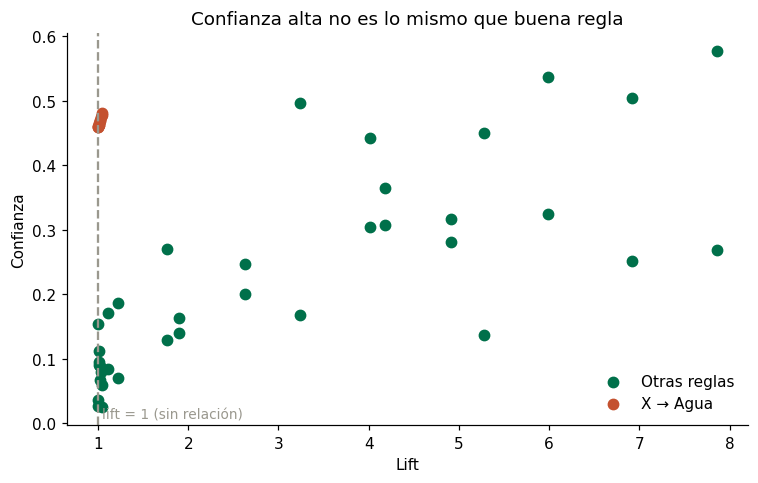

In [10]:
top_conf = reglas.sort_values("confidence", ascending=False).head(8)
print(top_conf.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4.5))
es_agua = reglas["B"] == "Agua"
ax.scatter(reglas.loc[~es_agua, "lift"], reglas.loc[~es_agua, "confidence"], color=VERDE, label="Otras reglas", s=45)
ax.scatter(reglas.loc[es_agua, "lift"], reglas.loc[es_agua, "confidence"], color=NARANJA, label="X → Agua", s=45)
ax.axvline(1, color=GRIS, ls="--"); ax.text(1.05, ax.get_ylim()[0] + 0.01, "lift = 1 (sin relación)", color=GRIS, fontsize=9)
ax.set_xlabel("Lift"); ax.set_ylabel("Confianza"); ax.legend(frameon=False)
ax.set_title("Confianza alta no es lo mismo que buena regla")
plt.tight_layout(); plt.show()

**Para discutir (anoten su respuesta, la vamos a pedir en la plenaria):**
1. ¿Por qué las reglas "X → Agua" tienen una confianza tan alta, y por qué su lift sale casi 1?
2. Si ofrecieran Agua a todo el que compra X, ¿venderían algo que no habrían vendido de todos modos?

Las reglas del tipo “X → Agua” muestran una confianza alta porque Agua es un producto que prácticamente todos compran, de modo que la probabilidad de encontrar Agua en cualquier canasta es elevada y, por extensión, también lo es la probabilidad de encontrarla cuando aparece X. Sin embargo, el lift cercano a uno revela que la presencia de X no incrementa la probabilidad de comprar Agua, sino que simplemente refleja la popularidad general del producto. En otras palabras, X no impulsa la compra de Agua; solo coincide con un artículo que ya se adquiere de manera habitual. 

Por eso, si se ofreciera Agua a quienes compran X, no se generarían ventas adicionales, ya que esos clientes habrían comprado Agua de todos modos.

## Paso 6 — de la regla a la decisión (ARPU)

Una regla A → B dice a quién ofrecerle B: a quienes compran A y **todavía no llevan B**. Esa es la oportunidad de venta cruzada.
Comparen las reglas buenas por el **ingreso potencial** si, por ejemplo, el 10% de esas canastas aceptara la oferta.

In [11]:
precio = items.set_index("item")["precio"]; margen = items.set_index("item")["margen"]
ACEPTA = 0.10     # supuesto: 10% acepta la oferta

filas = []
for _, r in buenas.iterrows():
    sin_B = (canastas[r["A"]] & ~canastas[r["B"]]).sum()          # canastas con A que no llevan B
    filas.append({"oferta": f'{r["A"]} → {r["B"]}', "lift": r["lift"], "canastas_oportunidad": sin_B,
                  "ingreso_potencial": sin_B * ACEPTA * precio[r["B"]],
                  "margen_potencial": sin_B * ACEPTA * precio[r["B"]] * margen[r["B"]]})
oportunidad = pd.DataFrame(filas).sort_values("margen_potencial", ascending=False)
oportunidad.round(1).head(8)

,oferta,lift,canastas_oportunidad,ingreso_potencial,margen_potencial
9,Galleta → Frappuccino,4.2,680,425.0,280.5
2,Americano → Sándwich,6.9,795,576.4,259.4
14,Galleta → Chocolate Caliente,1.8,781,363.2,239.7
11,Té Chai → Banana Bread,4.0,1121,409.2,225.0
12,Banana Bread → Té Chai,4.0,616,292.6,199.0
8,Muffin → Cappuccino,4.9,570,282.2,197.5
4,Latte → Croissant,6.0,883,348.8,191.8
1,Matcha Latte → Granola,7.9,784,333.2,166.6


3. El lift más alto, ¿es la oferta que más margen deja? ¿Por qué no coinciden?

El lift más alto no necesariamente corresponde a la oferta que deja más margen porque el lift mide relación estadística entre productos, no rentabilidad. Un par de productos puede tener un lift elevado simplemente porque se compran juntos con frecuencia, pero si alguno tiene poco margen o su precio es bajo, la combinación no genera más dinero. Por eso las reglas con mayor lift no coinciden con las que dejan más valor económico: el lift captura complementariedad en comportamiento, mientras que el margen depende de cuánto dinero aporta cada producto, dos dimensiones distintas.